In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("7817_1.csv")

print(df.shape)
df.head()

Saving 7817_1.csv to 7817_1.csv
(1597, 27)


,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight
0,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I initially had trouble deciding between the p...,"Paperwhite voyage, no regrets!",NaN,NaN,Cristina M,NaN,NaN,205 grams
1,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,Allow me to preface this with a little history...,One Simply Could Not Ask For More,NaN,NaN,Ricky,NaN,NaN,205 grams
2,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,4.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I am enjoying it so far. Great for reading. Ha...,Great for those that just want an e-reader,NaN,NaN,Tedd Gardiner,NaN,NaN,205 grams
3,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I bought one of the first Paperwhites and have...,Love / Hate relationship,NaN,NaN,Dougal,NaN,NaN,205 grams
4,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I have to say upfront - I don't like coroporat...,I LOVE IT,NaN,NaN,Miljan David Tanic,NaN,NaN,205 grams


In [ ]:
df = df[["reviews.text", "reviews.rating"]]

df.head()

,reviews.text,reviews.rating
0,I initially had trouble deciding between the p...,5.0
1,Allow me to preface this with a little history...,5.0
2,I am enjoying it so far. Great for reading. Ha...,4.0
3,I bought one of the first Paperwhites and have...,5.0
4,I have to say upfront - I don't like coroporat...,5.0


In [ ]:
# Remove rows with missing values
df = df.dropna()

# Remove duplicate reviews
df = df.drop_duplicates(subset="reviews.text")

# Remove empty reviews
df["reviews.text"] = df["reviews.text"].str.strip()
df = df[df["reviews.text"] != ""]

print("Dataset shape:", df.shape)
print(df.isnull().sum())

Dataset shape: (908, 2)
reviews.text      0
reviews.rating    0
dtype: int64


In [ ]:
def get_sentiment(rating):

    if rating <= 2:
        return 0       # Negative

    elif rating == 3:
        return 1       # Neutral

    else:
        return 2       # Positive


df["sentiment"] = df["reviews.rating"].apply(get_sentiment)

df.head()

,reviews.text,reviews.rating,sentiment
0,I initially had trouble deciding between the p...,5.0,2
1,Allow me to preface this with a little history...,5.0,2
2,I am enjoying it so far. Great for reading. Ha...,4.0,2
3,I bought one of the first Paperwhites and have...,5.0,2
4,I have to say upfront - I don't like coroporat...,5.0,2


sentiment
2    766
0     72
1     70
Name: count, dtype: int64


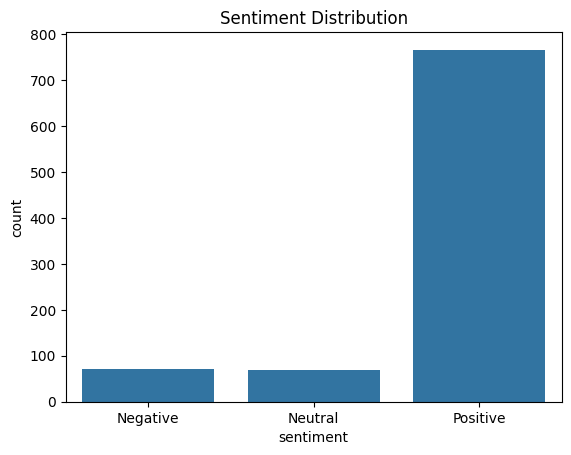

In [ ]:
print(df["sentiment"].value_counts())

sns.countplot(
    x="sentiment",
    data=df
)

plt.xticks(
    [0, 1, 2],
    ["Negative", "Neutral", "Positive"]
)

plt.title("Sentiment Distribution")
plt.show()

In [ ]:
X = df["reviews.text"].astype(str)
y = df["sentiment"]

# First, separate testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Separate validation data from training data
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.125,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 635
Validation samples: 91
Testing samples: 182


In [ ]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(4.150326797385621), np.int64(1): np.float64(4.319727891156463), np.int64(2): np.float64(0.3956386292834891)}


In [ ]:
max_words = 10000
max_len = 150

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

# Learn vocabulary from training reviews only
tokenizer.fit_on_texts(X_train)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Make all sequences equal in length
X_train_pad = pad_sequences(
    X_train_seq, maxlen=max_len, padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=max_len, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=max_len, padding="post", truncating="post"
)

print("Training shape:", X_train_pad.shape)

Training shape: (635, 150)


In [ ]:
lstm_model = Sequential([

    Embedding(max_words, 128),

    LSTM(64),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(3, activation="softmax")

])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
start = time.time()

history = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=32,
    class_weight=class_weights
)

lstm_train_time = time.time() - start

print("LSTM Training Time:", lstm_train_time)

Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 163ms/step - accuracy: 0.1874 - loss: 1.1059 - val_accuracy: 0.1538 - val_loss: 1.1036
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.3858 - loss: 1.1000 - val_accuracy: 0.8352 - val_loss: 1.0880
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 176ms/step - accuracy: 0.5165 - loss: 1.0931 - val_accuracy: 0.1429 - val_loss: 1.1192
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.2787 - loss: 1.0894 - val_accuracy: 0.1429 - val_loss: 1.1341
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.4346 - loss: 1.0823 - val_accuracy: 0.1429 - val_loss: 1.0937
LSTM Training Time: 20.225201845169067


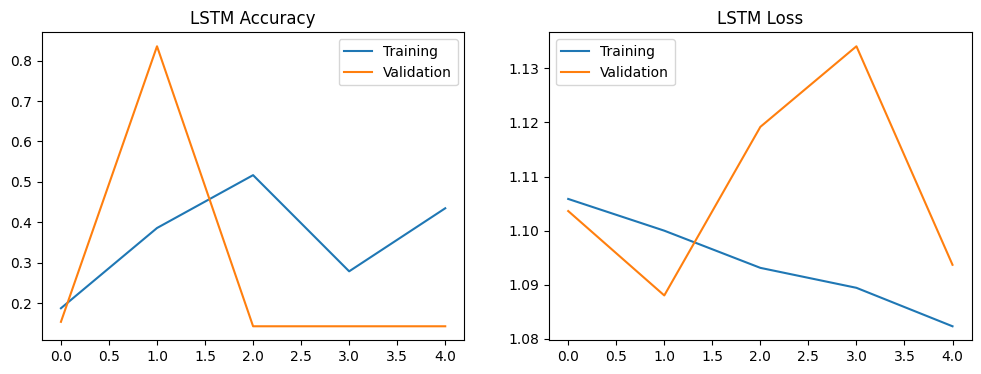

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("LSTM Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("LSTM Loss")
plt.legend()

plt.show()

In [ ]:
start = time.time()

lstm_pred = lstm_model.predict(X_test_pad)

lstm_inference_time = time.time() - start

lstm_pred = np.argmax(lstm_pred, axis=1)

print("LSTM Accuracy:", accuracy_score(y_test, lstm_pred))

print("\nClassification Report:")

print(classification_report(
    y_test,
    lstm_pred,
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

print("Macro F1:", f1_score(
    y_test,
    lstm_pred,
    average="macro"
))

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 294ms/step
LSTM Accuracy: 0.2087912087912088

Classification Report:
              precision    recall  f1-score   support

    Negative       0.08      0.86      0.15        14
     Neutral       0.25      0.07      0.11        14
    Positive       0.76      0.16      0.27       154

    accuracy                           0.21       182
   macro avg       0.36      0.36      0.18       182
weighted avg       0.67      0.21      0.25       182

Macro F1: 0.17647806216063708


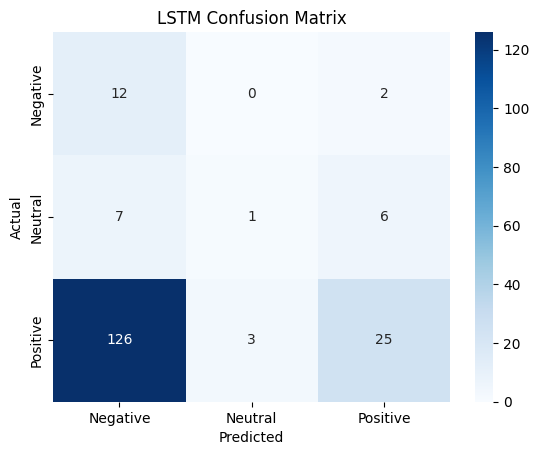

In [ ]:
cm = confusion_matrix(y_test, lstm_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LSTM Confusion Matrix")

plt.show()

In [ ]:
train_df = pd.DataFrame({
    "text": X_train.tolist(),
    "labels": y_train.tolist()
})

val_df = pd.DataFrame({
    "text": X_val.tolist(),
    "labels": y_val.tolist()
})

test_df = pd.DataFrame({
    "text": X_test.tolist(),
    "labels": y_test.tolist()
})

train_data = Dataset.from_pandas(train_df)
val_data = Dataset.from_pandas(val_df)
test_data = Dataset.from_pandas(test_df)

In [ ]:
model_name = "distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
def tokenize_function(examples):

    return bert_tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )


train_data = train_data.map(
    tokenize_function,
    batched=True
)

val_data = val_data.map(
    tokenize_function,
    batched=True
)

test_data = test_data.map(
    tokenize_function,
    batched=True
)

train_data = train_data.remove_columns(["text"])
val_data = val_data.remove_columns(["text"])
test_data = test_data.remove_columns(["text"])

Map:   0%|          | 0/635 [00:00<?, ? examples/s]

Map:   0%|          | 0/91 [00:00<?, ? examples/s]

Map:   0%|          | 0/182 [00:00<?, ? examples/s]

In [ ]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=bert_tokenizer
)

In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),

        "f1_macro": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }

In [ ]:
class_weights_tensor = torch.tensor(
    [class_weights[i] for i in range(3)],
    dtype=torch.float
)

In [ ]:
class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        loss_function = torch.nn.CrossEntropyLoss(
            weight=class_weights_tensor.to(model.device)
        )

        loss = loss_function(
            outputs.logits,
            labels
        )

        return (loss, outputs) if return_outputs else loss

In [ ]:
training_args = TrainingArguments(

    output_dir="./bert_results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",

    save_total_limit=1,

    report_to="none"
)

In [ ]:
trainer = WeightedTrainer(

    model=bert_model,

    args=training_args,

    train_dataset=train_data,

    eval_dataset=val_data,

    data_collator=data_collator,

    processing_class=bert_tokenizer,

    compute_metrics=compute_metrics
)

In [ ]:
start = time.time()

trainer.train()

bert_train_time = time.time() - start

print("BERT Training Time:", bert_train_time)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.944433,0.813187,0.550933
2,No log,1.806626,0.835165,0.481575


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [ ]:
start = time.time()

bert_output = trainer.predict(test_data)

bert_inference_time = time.time() - start

bert_pred = np.argmax(
    bert_output.predictions,
    axis=1
)

y_true = bert_output.label_ids

print("BERT Accuracy:", accuracy_score(y_true, bert_pred))

print("\nClassification Report:")

print(classification_report(
    y_true,
    bert_pred,
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

print("BERT Macro F1:", f1_score(
    y_true,
    bert_pred,
    average="macro"
))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


BERT Accuracy: 0.8846153846153846

Classification Report:
              precision    recall  f1-score   support

    Negative       0.61      0.79      0.69        14
     Neutral       0.38      0.21      0.27        14
    Positive       0.94      0.95      0.95       154

    accuracy                           0.88       182
   macro avg       0.64      0.65      0.64       182
weighted avg       0.87      0.88      0.88       182

BERT Macro F1: 0.6362047898338221


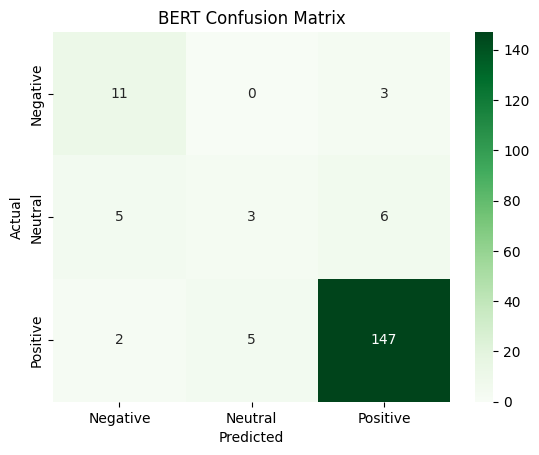

In [ ]:
cm = confusion_matrix(y_true, bert_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BERT Confusion Matrix")

plt.show()

In [ ]:
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro F1",
        "Training Time (seconds)",
        "Inference Time (seconds)"
    ],

    "LSTM": [
        accuracy_score(y_test, lstm_pred),
        f1_score(y_test, lstm_pred, average="macro"),
        lstm_train_time,
        lstm_inference_time
    ],

    "BERT": [
        accuracy_score(y_true, bert_pred),
        f1_score(y_true, bert_pred, average="macro"),
        bert_train_time,
        bert_inference_time
    ]

})

print(comparison.round(4).to_string(index=False))

                  Metric    LSTM      BERT
                Accuracy  0.2088    0.8846
                Macro F1  0.1765    0.6362
 Training Time (seconds) 20.2252 1506.8456
Inference Time (seconds)  2.6631   77.9666


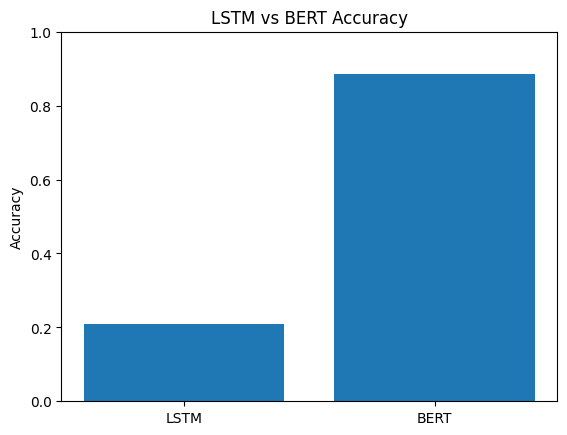

In [ ]:
models = ["LSTM", "BERT"]

accuracies = [
    accuracy_score(y_test, lstm_pred),
    accuracy_score(y_true, bert_pred)
]

plt.bar(models, accuracies)

plt.title("LSTM vs BERT Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

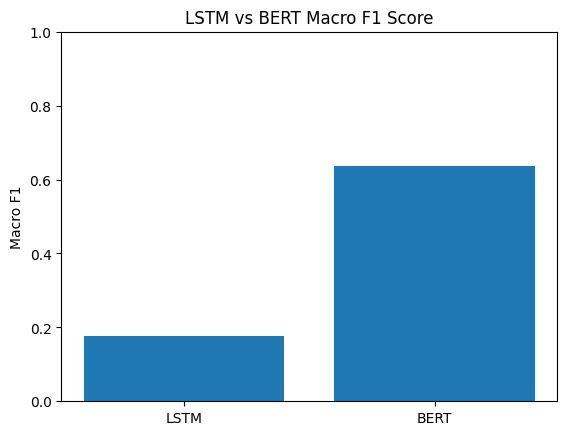

In [ ]:
f1_scores = [
    f1_score(y_test, lstm_pred, average="macro"),
    f1_score(y_true, bert_pred, average="macro")
]

plt.bar(models, f1_scores)

plt.title("LSTM vs BERT Macro F1 Score")
plt.ylabel("Macro F1")
plt.ylim(0, 1)

plt.show()

In [ ]:
review = ["The product is amazing and works perfectly. I absolutely love it!"]

# LSTM prediction
seq = tokenizer.texts_to_sequences(review)

pad = pad_sequences(
    seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

lstm_result = np.argmax(
    lstm_model.predict(pad, verbose=0),
    axis=1
)[0]


# BERT prediction
inputs = bert_tokenizer(
    review,
    return_tensors="pt",
    truncation=True,
    max_length=128
)

inputs = {
    key: value.to(bert_model.device)
    for key, value in inputs.items()
}

bert_model.eval()

with torch.no_grad():
    outputs = bert_model(**inputs)

bert_result = torch.argmax(
    outputs.logits,
    dim=1
).item()


sentiments = ["Negative", "Neutral", "Positive"]

print("LSTM Prediction:", sentiments[lstm_result])
print("BERT Prediction:", sentiments[bert_result])

LSTM Prediction: Negative
BERT Prediction: Positive
